# Teoría de Inventarios

En este notebook voy a revisar algunos modelos de inventarios que vienen en las notas del profesor. Voy a usar Python para hacer los cálculos y también algunas gráficas para ver mejor los resultados.

## 1. Conceptos básicos

El inventario son los productos que una empresa tiene guardados para poder atender la demanda. La idea es decidir cuánto pedir y cuándo pedirlo, tratando de que no se gaste demasiado en pedidos o almacenamiento.

| Símbolo | Qué significa |
|---|---|
| D | Demanda por año |
| K | Costo de hacer un pedido |
| h | Costo de mantener una unidad |
| p | Costo de faltantes pendientes |
| Q | Cantidad que se pide |
| T | Tiempo entre pedidos |
| L | Tiempo de entrega |
| P | Ritmo de producción |

Los modelos cambian dependiendo de si la demanda es fija o aleatoria, si se permiten faltantes y si el inventario llega de golpe o se va produciendo.


## 2. EOQ clásico

Este modelo se usa cuando la demanda es constante, los pedidos llegan de inmediato y no se permiten faltantes.

La función de costo que se minimiza es:

\[ C(Q)=\frac{KD}{Q}+\frac{hQ}{2} \]

La cantidad económica de pedido es:

\[ Q^*=\sqrt{\frac{2KD}{h}} \]

En el punto óptimo, los costos de ordenar y de mantener inventario quedan iguales.


In [1]:
# Importamos las librerías que vamos a usar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import poisson, norm
from scipy.optimize import brentq

In [2]:
# Usamos los datos del ejemplo del PDF y calculamos Q
# Ejemplo de las notas: D=12,000; K=180; h=6
D, K, h = 12000., 180., 6.
Q_eoq = np.sqrt(2*K*D/h)
C_eoq = K*D/Q_eoq + h*Q_eoq/2
n_orders = D/Q_eoq
cycle_days = 300*Q_eoq/D
ordering = K*n_orders
holding = h*Q_eoq/2
print(f'EOQ: {Q_eoq:.2f} unidades')
print(f'Costo relevante mínimo anual: {C_eoq:,.2f}')
print(f'Pedidos/año: {n_orders:.2f}; días por ciclo: {cycle_days:.2f}')
print(f'Ordenar={ordering:,.2f}; mantener={holding:,.2f}')

EOQ: 848.53 unidades
Costo relevante mínimo anual: 5,091.17
Pedidos/año: 14.14; días por ciclo: 21.21
Ordenar=2,545.58; mantener=2,545.58


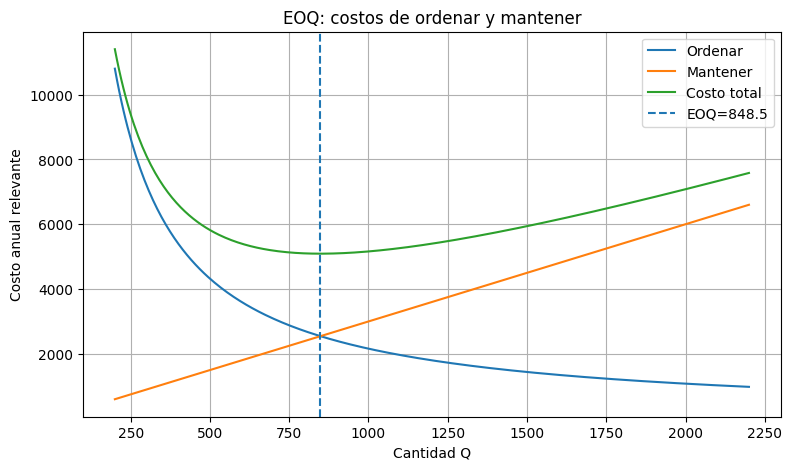

In [3]:
# Graficamos los costos para diferentes cantidades de pedido
q = np.linspace(200,2200,300)
co = K*D/q
ch = h*q/2
ct = co+ch
plt.figure(figsize=(9,5))
plt.plot(q,co,label='Ordenar')
plt.plot(q,ch,label='Mantener')
plt.plot(q,ct,label='Costo total')
plt.axvline(Q_eoq,linestyle='--',label=f'EOQ={Q_eoq:.1f}')
plt.xlabel('Cantidad Q'); plt.ylabel('Costo anual relevante')
plt.title('EOQ: costos de ordenar y mantener'); plt.grid(True); plt.legend(); plt.show()

## 3. EOQ cuando se permiten faltantes (backorders)

En este caso, si no hay producto, el cliente espera y el pedido pendiente se entrega después. Se divide el ciclo en inventario disponible (S) y faltante (B), de modo que Q=S+B.

\[ Q^*=\sqrt{\frac{2KD(h+p)}{hp}},\quad S=\frac{p}{h+p}Q,\quad B=\frac{h}{h+p}Q \]

El costo anual incluye ordenar, mantener inventario y tener pedidos pendientes.


In [4]:
# Calculamos el lote, inventario máximo y faltantes
D,K,h,p = 12000.,180.,6.,24.
Q_bo = np.sqrt(2*K*D*(h+p)/(h*p))
S = Q_bo*p/(h+p); B = Q_bo*h/(h+p)
order_bo = K*D/Q_bo
hold_bo = h*S**2/(2*Q_bo)
backlog_cost = p*B**2/(2*Q_bo)
C_bo = order_bo+hold_bo+backlog_cost
print(f'Q*={Q_bo:.2f}; S*={S:.2f}; B*={B:.2f}')
print(f'Costo anual={C_bo:,.2f}; ordenar={order_bo:,.2f}; mantener={hold_bo:,.2f}; backlog={backlog_cost:,.2f}')

Q*=948.68; S*=758.95; B*=189.74
Costo anual=4,553.68; ordenar=2,276.84; mantener=1,821.47; backlog=455.37


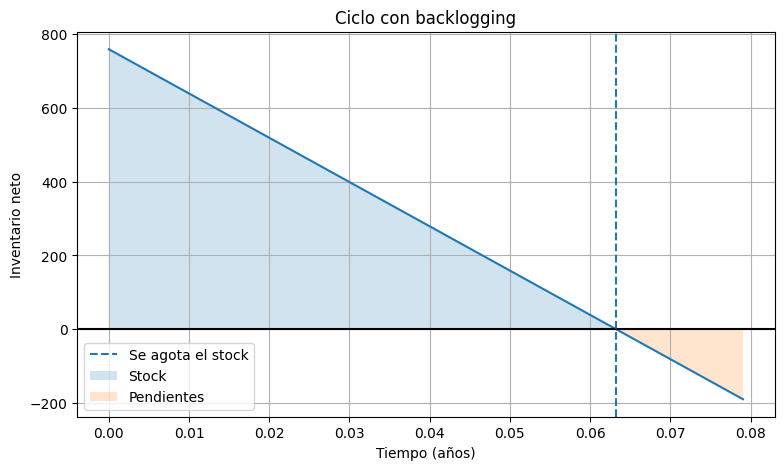

In [5]:
# Gráfica del inventario durante un ciclo
t_cycle=Q_bo/D
x=np.linspace(0,t_cycle,300); inv=S-D*x
plt.figure(figsize=(9,5)); plt.plot(x,inv); plt.axhline(0,color='black'); plt.axvline(S/D,linestyle='--',label='Se agota el stock')
plt.fill_between(x,inv,0,where=inv>=0,alpha=.2,label='Stock')
plt.fill_between(x,inv,0,where=inv<0,alpha=.2,label='Pendientes')
plt.xlabel('Tiempo (años)'); plt.ylabel('Inventario neto'); plt.title('Ciclo con backlogging'); plt.legend(); plt.grid(True); plt.show()

## 4. Ventas perdidas

Aquí, si no hay producto el cliente ya no compra y la venta se pierde. No se acumula como un pedido pendiente.

\[ g(S)=h_oE(S-N)^+ + c_uE(N-S)^+ \]

Para elegir el inventario se usa la fracción crítica:

\[ \frac{c_u}{c_u+h_o} \]

Se elige el primer nivel de inventario cuya probabilidad acumulada alcance esa fracción.


In [6]:
# Calculamos el nivel de inventario con demanda Poisson
# Ejemplo de notas: Poisson(22), costo sobrante 2, costo faltante 17
mu, ho, cu = 22, 2, 17
critical=cu/(cu+ho)
S_lost=int(poisson.ppf(critical,mu))
levels=np.arange(100); n=np.arange(150); prob=poisson.pmf(n,mu)
costs=[np.sum(prob*(ho*np.maximum(s-n,0)+cu*np.maximum(n-s,0))) for s in levels]
print('Fracción crítica:',round(critical,4),'Inventario óptimo:',S_lost,'Costo:',round(costs[S_lost],2))

Fracción crítica: 0.8947 Inventario óptimo: 28 Costo: 16.88


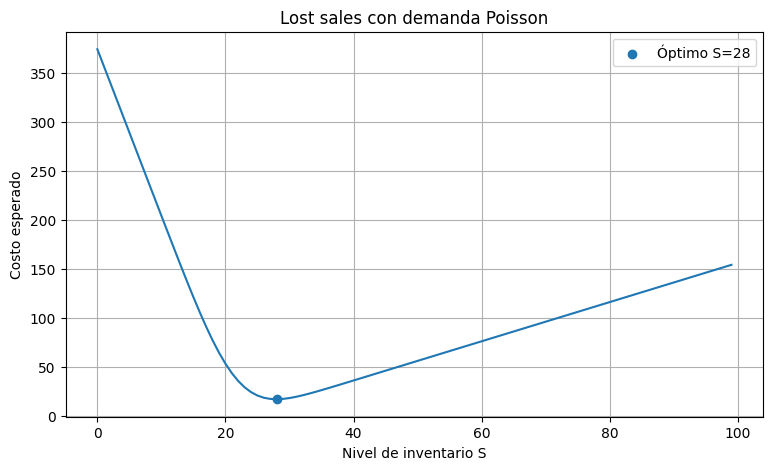

In [7]:
# Comparamos el costo esperado para distintos niveles
plt.figure(figsize=(9,5)); plt.plot(levels,costs); plt.scatter([S_lost],[costs[S_lost]],label=f'Óptimo S={S_lost}')
plt.xlabel('Nivel de inventario S'); plt.ylabel('Costo esperado'); plt.title('Lost sales con demanda Poisson'); plt.grid(True); plt.legend(); plt.show()

## 5. Lotes enteros

Si la cantidad que se pide tiene que ser un número entero, primero calculamos el EOQ normal y después comparamos los dos enteros cercanos (redondeo hacia abajo y hacia arriba). Se escoge el que tenga menor costo.


In [8]:
# Comparamos los dos enteros más cercanos al EOQ
q0=np.sqrt(2*K*D/h)
opts=[max(1,int(np.floor(q0))),int(np.ceil(q0))]
integer_costs={q:K*D/q+h*q/2 for q in opts}
print('EOQ continuo:',q0,'Costos candidatos:',integer_costs)
print('Lote entero elegido:',min(integer_costs,key=integer_costs.get))

EOQ continuo: 848.5281374238571 Costos candidatos: {848: 5091.169811320755, 849: 5091.16961130742}
Lote entero elegido: 849


## 6. Producción finita (EPQ)

En este modelo los artículos se producen mientras también hay demanda. La tasa de producción P tiene que ser mayor que D.

\[ I_{max}=Q(1-D/P) \]

\[ Q^*_{EPQ}=\sqrt{\frac{2KD}{h(1-D/P)}} \]

Como se consume producto mientras se produce, el inventario máximo es menor que el lote producido.


In [9]:
# Calculamos el tamaño del lote de producción
D,K,h,P=12000.,180.,6.,48000.
factor=1-D/P
Q_epq=np.sqrt(2*K*D/(h*factor)); Imax=Q_epq*factor
C_epq=K*D/Q_epq+h*Imax/2
prod_time=Q_epq/P; cyc_time=Q_epq/D
print(f'EPQ={Q_epq:.2f}; inventario máximo={Imax:.2f}; costo anual={C_epq:,.2f}')
print(f'Duración producción={prod_time:.5f} años; duración ciclo={cyc_time:.5f} años')

EPQ=979.80; inventario máximo=734.85; costo anual=4,409.08
Duración producción=0.02041 años; duración ciclo=0.08165 años


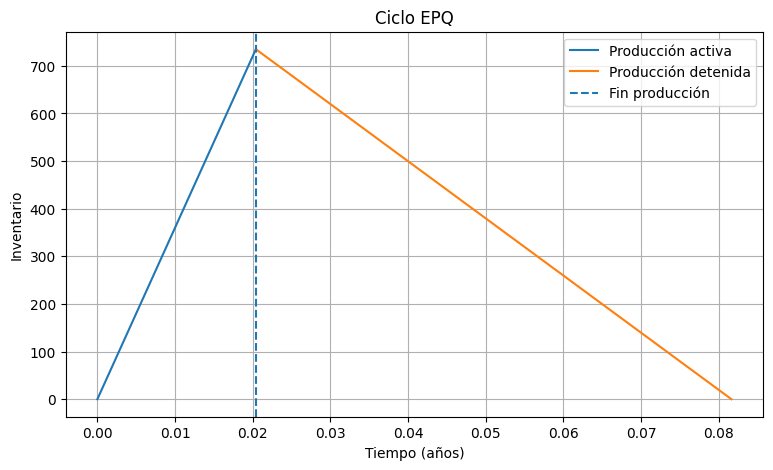

In [10]:
# Gráfica del inventario mientras se produce y después
t1=np.linspace(0,prod_time,100); inv1=(P-D)*t1
t2=np.linspace(prod_time,cyc_time,150); inv2=Imax-D*(t2-prod_time)
plt.figure(figsize=(9,5)); plt.plot(t1,inv1,label='Producción activa'); plt.plot(t2,inv2,label='Producción detenida'); plt.axvline(prod_time,linestyle='--',label='Fin producción')
plt.xlabel('Tiempo (años)'); plt.ylabel('Inventario'); plt.title('Ciclo EPQ'); plt.grid(True); plt.legend(); plt.show()

## 7. Newsvendor

Este modelo es para decidir cuánto pedir antes de conocer la demanda. Si sobran productos hay un costo, y si faltan también hay un costo.

\[ G(q)=c_oE(q-N)^+ + c_uE(N-q)^+ \]

La fracción crítica es \(c_u/(c_o+c_u)\). En el ejemplo la demanda se modela con Poisson, y se busca la cantidad que minimiza el costo esperado.


In [11]:
# Calculamos la cantidad recomendada en el ejemplo Newsvendor
# Ejemplo: Poisson(35), cu=18, co=5
mu,cu,co=35,18.,5.
q_news=int(poisson.ppf(cu/(cu+co),mu))
d=np.arange(150); loss=np.sum(poisson.pmf(d,mu)*(co*np.maximum(q_news-d,0)+cu*np.maximum(d-q_news,0)))
print(f'Fracción crítica={cu/(cu+co):.5f}; q*={q_news}; costo esperado={loss:.2f}')

Fracción crítica=0.78261; q*=40; costo esperado=40.89


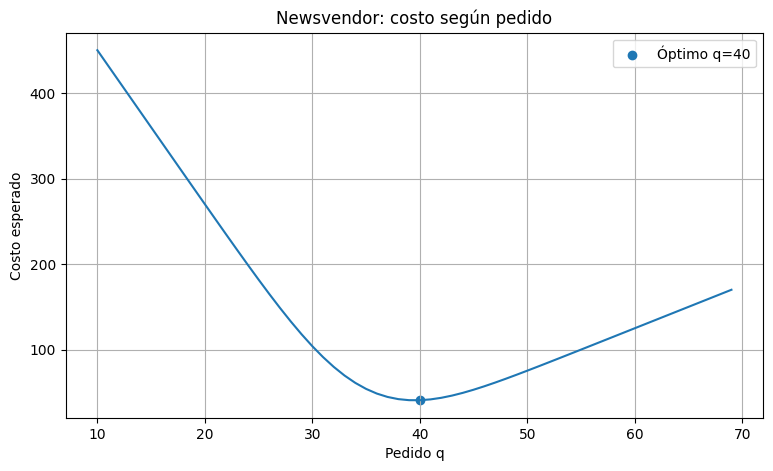

In [12]:
# Graficamos el costo esperado para distintas cantidades
q_vals=np.arange(10,70)
losses=[np.sum(poisson.pmf(d,mu)*(co*np.maximum(q-d,0)+cu*np.maximum(d-q,0))) for q in q_vals]
plt.figure(figsize=(9,5)); plt.plot(q_vals,losses); plt.scatter([q_news],[loss],label=f'Óptimo q={q_news}')
plt.xlabel('Pedido q'); plt.ylabel('Costo esperado'); plt.title('Newsvendor: costo según pedido'); plt.grid(True); plt.legend(); plt.show()

## 8. Política de revisión continua (Q,R)

Se pide una cantidad Q cuando la posición del inventario llega al punto R.

Para un nivel de servicio \alpha, se busca que:

\[ P(N_L\le R)\ge\alpha \]

Si la demanda diaria es independiente y el tiempo de entrega es fijo:

\[ R\approx L\mu_d+z_\alpha\sigma_d\sqrt L \]

El segundo término es el inventario de seguridad.


In [13]:
# Calculamos el punto de reorden para el ejemplo de 95%
# Ejemplo: mu diaria 40, sd 16, lead time 5 días, servicio 95%
mu_d,sd_d,L,alpha=40,16,5,.95
mean_lt=L*mu_d; sd_lt=sd_d*np.sqrt(L); z=norm.ppf(alpha)
R=mean_lt+z*sd_lt
print(f'Media lead time={mean_lt:.2f}; desviación={sd_lt:.2f}; z={z:.5f}')
print(f'R={R:.2f}; entero sugerido={int(np.ceil(R))}')

Media lead time=200.00; desviación=35.78; z=1.64485
R=258.85; entero sugerido=259


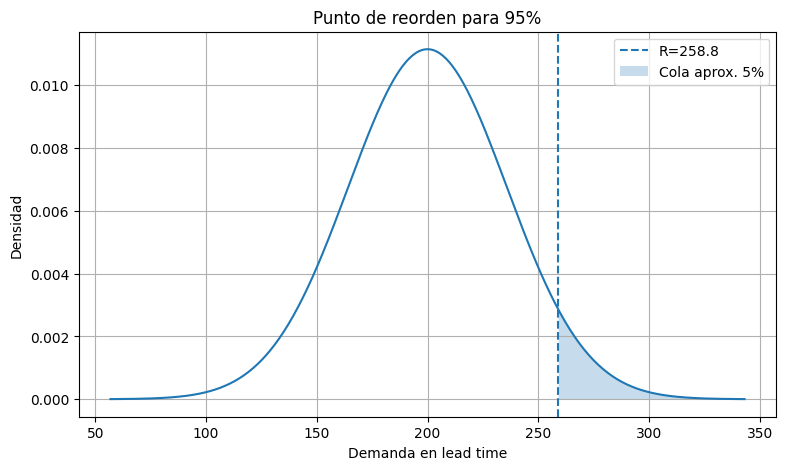

In [14]:
# Gráfica de la demanda durante el tiempo de entrega
xx=np.linspace(mean_lt-4*sd_lt,mean_lt+4*sd_lt,400); yy=norm.pdf(xx,loc=mean_lt,scale=sd_lt)
plt.figure(figsize=(9,5)); plt.plot(xx,yy); plt.axvline(R,linestyle='--',label=f'R={R:.1f}'); plt.fill_between(xx,yy,where=xx>=R,alpha=.25,label='Cola aprox. 5%')
plt.xlabel('Demanda en lead time'); plt.ylabel('Densidad'); plt.title('Punto de reorden para 95%'); plt.grid(True); plt.legend(); plt.show()

## 9. Varios productos y presupuesto

Si se manejan varios productos, puede que las cantidades óptimas normales no quepan en el presupuesto. Para esta restricción se usa un multiplicador \lambda:

\[ Q_i(\lambda)=\sqrt{\frac{2K_iD_i}{h_i+2\lambda c_i}} \]

Si el EOQ normal alcanza el presupuesto, no hace falta ajustar. Si lo rebasa, se calcula un valor de \	extlambda que permita respetar el límite.


In [15]:
# Encontramos las cantidades cuando hay límite de presupuesto
# Ejemplo de notas: 3 artículos, presupuesto M=13,000
Ds=np.array([12000.,8000.,5000.]); Ks=np.array([180.,120.,90.]); hs=np.array([6.,4.,3.]); cs=np.array([20.,35.,25.]); M_budget=13000.
def q_lam(lam): return np.sqrt(2*Ks*Ds/(hs+2*lam*cs))
q_free=q_lam(0); budget_free=cs@q_free
if budget_free<=M_budget: lam=0.
else:
    upper=1.
    while cs@q_lam(upper)>M_budget: upper*=2
    lam=brentq(lambda x:cs@q_lam(x)-M_budget,0,upper)
q_limited=q_lam(lam); annual_cost=np.sum(Ks*Ds/q_limited+hs*q_limited/2)
print('EOQ libre:',np.round(q_free,2),'Presupuesto libre:',budget_free)
print('Lambda:',lam,'Lotes con presupuesto:',np.round(q_limited,2))
print('Presupuesto aplicado:',cs@q_limited,'Costo anual relevante:',annual_cost)

EOQ libre: [848.53 692.82 547.72] Presupuesto libre: 54912.33799207057
Lambda: 1.3673312889807192 Lotes con presupuesto: [266.79 138.76 112.3 ]
Presupuesto aplicado: 12999.999999999976 Costo anual relevante: 20268.00281373145


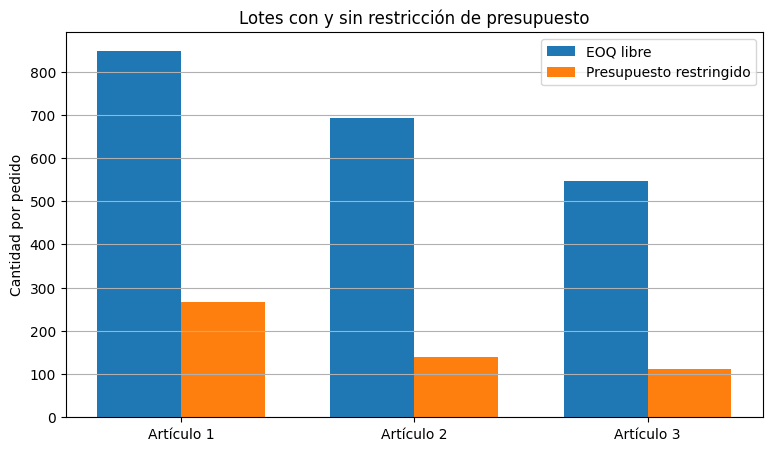

In [16]:
# Comparamos cantidades libres y con presupuesto limitado
names=['Artículo 1','Artículo 2','Artículo 3']; pos=np.arange(3); w=.36
plt.figure(figsize=(9,5)); plt.bar(pos-w/2,q_free,w,label='EOQ libre'); plt.bar(pos+w/2,q_limited,w,label='Presupuesto restringido')
plt.xticks(pos,names); plt.ylabel('Cantidad por pedido'); plt.title('Lotes con y sin restricción de presupuesto'); plt.grid(axis='y'); plt.legend(); plt.show()

## 10. Comentarios finales

- En el EOQ se busca equilibrar el costo de pedir y el de guardar productos.
- Si se permiten faltantes, hay que distinguir entre pedidos pendientes y ventas que se pierden.
- En los modelos con demanda aleatoria, la cantidad se decide tomando en cuenta la probabilidad y los costos.
- En la política (Q,R), Q es cuánto pedir y R cuándo hacer el pedido.
- Cuando hay límites de presupuesto, no siempre sirve redondear las cantidades por separado; hay que revisar que sí se cumpla la restricción.

